### Get data

In [2]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit
import tensorflow as tf

2025-04-08 17:14:39.533606: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-08 17:14:39.534398: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-04-08 17:14:39.540058: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-04-08 17:14:39.559326: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-04-08 17:14:39.597540: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been 

In [5]:
p=[21.3,23.3,24.8,25,31.2,33.5,35,28.5,27.5]
q=[70.5, 68.5, 55, 53, 46, 41, 40, 46.5, 47]

In [14]:
p1 = [1/x for x in p]
q1= [1/x for x in q]

In [15]:
x = np.array(p1)
y = np.array(q1)

In [24]:
sigma_x = np.full(len(x), 0.005)
sigma_y = np.full(len(x), 0.005)

### Fit

$\frac{1}{q} = -\frac{1}{p}+\frac{1}{f}$

y = -x + q  

only extimate q  


In [17]:
# Model with fixed slope m = -1: y = -x + q
def fit_model_fixed_slope(x, q):
    return -x + q

# Your data

# Fit only q (intercept = 1/f)
popt, pcov = curve_fit(fit_model_fixed_slope, x, y)
q_hat = popt[0]
sigma_q = np.sqrt(pcov[0, 0])

# Estimated focal length and dioptric power
f_est = 1 / q_hat
D_est = q_hat  # dioptric power in diopters

# Output
print(f"Estimated 1/f = {q_hat:.3f} ± {sigma_q:.3f} (1/m)")
print(f"Estimated focal length f = {f_est:.3f} m")
print(f"Estimated dioptric power D = {D_est:.3f} diopters")

Estimated 1/f = 0.057 ± 0.001 (1/m)
Estimated focal length f = 17.583 m
Estimated dioptric power D = 0.057 diopters


Estimated 1/f = 0.057 ± 0.001 (1/m)
Estimated focal length f = 17.583 m
Estimated dioptric power D = 0.057 diopters


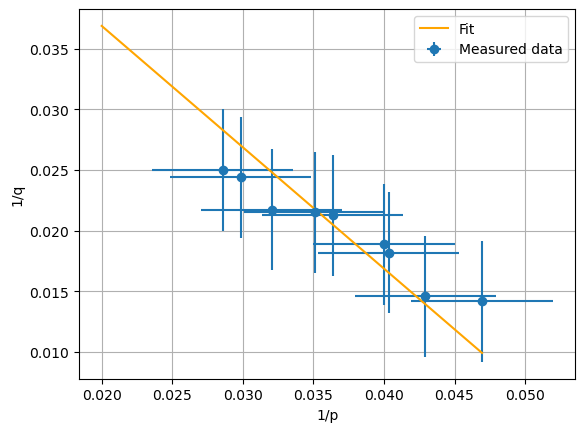

In [25]:

# Output
print(f"Estimated 1/f = {q_hat:.3f} ± {sigma_q:.3f} (1/m)")
print(f"Estimated focal length f = {f_est:.3f} m")
print(f"Estimated dioptric power D = {D_est:.3f} diopters")

# Optional: Plot
x_fit = np.linspace(0.02, max(x), 100)
y_fit = fit_model_fixed_slope(x_fit, *popt)

plt.errorbar(x, y, sigma_x, sigma_y, fmt='o', label='Measured data') 
plt.plot(x_fit, y_fit, label='Fit', color='orange')

plt.xlabel('1/p')
plt.ylabel('1/q')
plt.grid(True)
plt.legend()
plt.show()


### Chi

In [26]:
import numpy as np
import tensorflow as tf
from scipy.optimize import curve_fit


# Convert x to TensorFlow tensor
x_tf = tf.convert_to_tensor(x, dtype=tf.float64)

# Compute the first fit (ignoring errors on x)
popt, pcov = curve_fit(fit_model_fixed_slope, x, y, sigma=sigma_y)

# Define a function to compute the derivative of the model
def compute_derivative(x_val, params):
    with tf.GradientTape() as tape:
        tape.watch(x_val)
        y_pred = fit_model_fixed_slope(x_val, *params)
    return tape.gradient(y_pred, x_val)  # Compute dy/dx

# Iteratively update errors and refit
for i in range(3):
    # Compute the propagated error using automatic differentiation
    df_dx = compute_derivative(x_tf, popt).numpy()  # Convert TF tensor to NumPy array
    sigma_eff = np.sqrt(sigma_y**2 + (df_dx * sigma_x)**2)  # Total effective error
    
    # Refit with updated sigma_eff
    popt, pcov = curve_fit(fit_model_fixed_slope, x, y, sigma=sigma_eff)
    
    # Compute chi-square
    chisq = np.sum(((y - fit_model_fixed_slope(x, *popt)) / sigma_eff) ** 2)
    
    # Print results
    print(f'Step {i + 1}...')
    print(f'Parameters: {popt}')
    print(f'Errors: {np.sqrt(np.diag(pcov))}')
    print(f'Chi-square: {chisq:.2f}')

Step 1...
Parameters: [0.05687314]
Errors: [0.00085958]
Chi-square: 1.06
Step 2...
Parameters: [0.05687314]
Errors: [0.00085958]
Chi-square: 1.06
Step 3...
Parameters: [0.05687314]
Errors: [0.00085958]
Chi-square: 1.06
